In the same way that a 3x3 filter can look over a patch of an image, a 1x2 filter can look over a 2 sequential words in a piece of text, i.e. a bi-gram. Here, we will use multiple filters of different sizes which will look at the bi-grams (a 1x2 filter), tri-grams (a 1x3 filter) and/or n-grams (a 1xn filter) within the text.

The intuition here is that the appearance of certain bi-grams, tri-grams and n-grams within the text will be a good indication of the news group.

In [22]:
!pip install torchtext torchdata --index-url https://download.pytorch.org/whl/cu118

Looking in indexes: https://download.pytorch.org/whl/cu118


In [23]:
!pip install "numpy<2"

In [24]:
!pip install portalocker>=2.0.0

In [25]:
import torch, torchtext

from torchtext.datasets import AG_NEWS
from torchtext.data.utils import get_tokenizer
from torchtext.vocab import FastText, build_vocab_from_iterator

from torch import nn as nn
from torch.nn import functional as F
from torch.utils.data import DataLoader
from torch.nn.utils.rnn import pad_sequence

import matplotlib.pyplot as plt

import time

SEED = 1234
torch.manual_seed(SEED)
torch.backends.cudnn.determinstic = True

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [26]:
# Prepare Dataset
train, test = AG_NEWS()

train_length = len(list(iter(train)))
train, val, rem = train.random_split(total_length=train_length, weights={"train": 0.2, "val": 0.1, "rem": 0.7}, seed=SEED)

train_size_length = len(list(iter(train)))
val_size_length = len(list(iter(val)))
test_size_length = len(list(iter(test)))

print("Train {}, Val: {}, Test: {}".format(train_size_length, val_size_length, test_size_length))

Train 24000, Val: 12000, Test: 7600


In [27]:
# Build the vocab and dictionaries and numericalize

tokenizer = get_tokenizer(tokenizer="spacy", language="en_core_web_sm")

def yield_tokens(train_data):
    for _label, _text in train:
        tokens =  tokenizer(_text)
        yield tokens

word2idx = build_vocab_from_iterator(yield_tokens(train), specials=["<unk>", "<pad>", "<bos>", "<eos>"])
word2idx.set_default_index(word2idx["<unk>"])
idx2word = word2idx.get_itos()
vocab_size = len(word2idx)

pad_idx = word2idx["<pad>"]  # making sure our embedding layer ignores pad

print("Total Vocab: {}".format(vocab_size))

Total Vocab: 52564


### Design the model
The first major hurdle is visualizing how CNNs are used for text. Images are typically 2 dimensional (we'll ignore the fact that there is a third channel i.e "colour" dimension for now) whereas text is 1 dimensional.

Consider the 2 dimensional representation of the embedded sentence below:

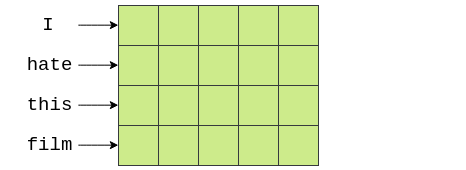

We can then use a filter that is `[n x emb_dim]`. This will cover `n` sequential words entirely, as their width will be emb_dim dimensions.

Consider the image below, with our word vectors are represented in green. Here we have `4 words with 5 dimensional embeddings`, creating a `[4x5]` "image" tensor. A filter that covers two words at a time (i.e. bi-grams) will be `[2x5] filter`, shown in yellow, and each element of the filter with have a weight associated with it.

The output of this filter (shown in red) will be a single real number that is the weighted sum of all elements covered by the filter. We get after applying the pooling layer. It represents the relation between the associated bigrams.

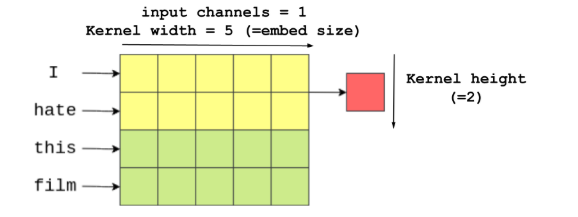


The filter then moves "down" the image (or across the sentence) to cover the next bi-gram and another output (weighted sum) is calculated.

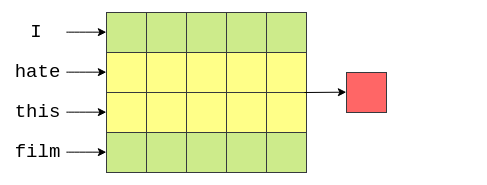

Finally, the filter moves down again and the final output for this filter is calculated.

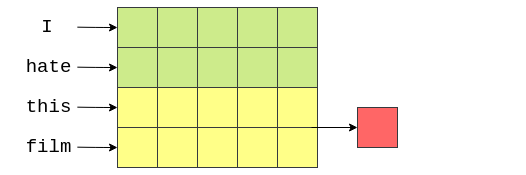

In our case , our `output` will be a vector with number of elements equal to the `height of the image (or length of the word) minus the height of the filter plus one`, `4-2+1` in this case.

Note:
Usually, for convolution in case of image, the output size is generally
` (n + 2p - f) / s + 1`, where:
- n: is the input size (height and width).
- p: is the padding added to the input.
- f: is the filter size.
- s: is the stride

In our model, we will also have different sizes of filters, heights of 3, 4 and 5, with 100 of each of them. The intuition is that we will be looking for the occurence of different tri-grams, 4-grams and 5-grams that are relevant for classification.

The next step in our model is to use pooling (specifically max pooling) on the output of the convolutional layers. Below an example of taking the maximum value (0.9) from the output of the convolutional layer on the example sentence (after the activation function applied to the output of the convolutions).

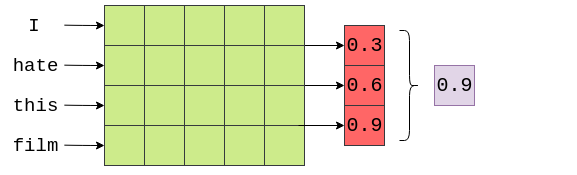

The idea here is that the maximum value is the "most important" feature for prediction, which corresponds to the "most important" n-gram within the text. How do we know what the "most important" n-gram is? Luckily, we don't have to! Through backpropagation, the weights of the filters are changed so that whenever certain n-grams that are highly indicative of the labels, the output of the filter is a "high" value. This "high" value then passes through the max pooling layer if it is the maximum value in the output.

Note: Another nice feature of the pooling layers is that they handle sentences of different lengths. The size of the output of the convolutional layer is dependent on the size of the input to it, and different batches contain sentences of different lengths. Without the max pooling layer the input to our linear layer would depend on the size of the input sentence (not what we want). One option to rectify this would be to trim/pad all sentences to the same length, however with the max pooling layer we always know the input to the linear layer will be the total number of filters.

As our model has 100 filters of 3 different sizes, that means we have 300 different n-grams the model thinks are important. We concatenate these together into a single vector and pass them through a linear layer to predict the sentiment. We can think of the weights of this linear layer as "weighting up the evidence" from each of the 300 n-grams and making a final decision.

**Implementation Details**

We implement the convolutional layers with nn.Conv2d. The in_channels argument is the number of "channels" in your image going into the convolutional layer. In actual images this is usually 3 (one channel for each of the red, blue and green channels), however when using text we only have a single channel, the text itself. The out_channels is the number of filters and the kernel_size is the size of the filters. Each of our kernel_sizes is going to be [n x emb_dim] where `n` is the size of the n-grams.

The second dimension of the input into a nn.Conv2d layer must be the channel dimension. As text technically does not have a channel dimension, we unsqueeze our tensor to create one. This matches with our in_channels=1 in the initialization of our convolutional layers.

We then pass the tensors through the convolutional and pooling layers, using the ReLU activation function after the convolutional layers. Note: there an exception to this if your sentence(s) are shorter than the largest filter used. You will then have to pad your sentences to the length of the largest filter. In our dataset there are no text smaller than 5 words long so we don't have to worry about that, but you will if you are using your own data.

Finally, we perform dropout on the concatenated filter outputs and then pass them through a linear layer to make our predictions.

In [28]:
class CNNModel(nn.Module):
    def __init__(self, input_dim, embed_dim, output_dim, n_filters, filter_sizes, dropout, pad_idx):
        super(CNNModel, self).__init__()
        self.embeddings = nn.Embedding(input_dim, embed_dim, padding_idx=pad_idx)
        self.conv0_trig = nn.Conv2d(in_channels=1, out_channels=n_filters, kernel_size=(filter_sizes[0], embed_dim), stride=1, padding=0)
        self.conv1_quadg = nn.Conv2d(in_channels=1, out_channels=n_filters, kernel_size=(filter_sizes[1], embed_dim))
        self.conv2_fiveg = nn.Conv2d(in_channels=1, out_channels=n_filters, kernel_size=(filter_sizes[2], embed_dim))
        self.dropout = nn.Dropout(p=dropout)
        self.fc = nn.Linear(in_features=n_filters*len(filter_sizes), out_features=output_dim)

    def forward(self, input):
        embeds = self.embeddings(input)                                               # (bs, seq_len) -> (bs, seq_len, embed_dim)

        # Add channel dimension
        embeds = embeds.unsqueeze(dim=1)                                               # (bs, 1, seq_len, embed_dim)  # visualize it as image

        conv_0 = F.relu(self.conv0_trig(embeds).squeeze(dim=3))                         # (bs, n_filters, seq_len - filter_sizes[n] + 1, 1)
        conv_1 = F.relu(self.conv1_quadg(embeds).squeeze(dim=3))                        # (bs, n_filters, seq_len - filter_sizes[n] + 1, 1)
        conv_2 = F.relu(self.conv2_fiveg(embeds).squeeze(dim=3))                        # (bs, n_filters, seq_len - filter_sizes[n] + 1, 1)

        pool_0 = F.max_pool1d(input=conv_0, kernel_size=conv_0.shape[2]).squeeze(2)     # (bs, n_filters, 1)
        pool_1 = F.max_pool1d(input=conv_1, kernel_size=conv_1.shape[2]).squeeze(2)     # (bs, n_filters, 1)
        pool_2 = F.max_pool1d(input=conv_2, kernel_size=conv_2.shape[2]).squeeze(2)     # (bs, n_filters, 1)

        final_cat = self.dropout(torch.cat((pool_0, pool_1, pool_2), dim=1))            # (bs, n_filters*len(filter_sizes))
        logits = self.fc(final_cat)
        return logits

In [29]:
# test
input = torch.randint(0, vocab_size, size=(64, 256))
input.shape

torch.Size([64, 256])

In [30]:
input.max(), input.min()

(tensor(52561), tensor(0))

In [31]:
emb_dim = 300
embeddings = nn.Embedding(vocab_size, emb_dim, padding_idx=pad_idx)
embedded = embeddings(input)
embedded.shape

torch.Size([64, 256, 300])

In [32]:
n_filters    = 100
filter_sizes = [3, 4, 5]

conv_0 = nn.Conv2d(in_channels=1, out_channels=n_filters, kernel_size=(filter_sizes[0], emb_dim))

In [33]:
embedded = embedded.unsqueeze(1)

In [34]:
embedded.shape

torch.Size([64, 1, 256, 300])

In [35]:
conv0_embedded = conv_0(embedded)

In [36]:
conv0_embedded.shape  # the last dim is 1 because it is the weighted sum

torch.Size([64, 100, 254, 1])

In [37]:
conv0_embedded_squeezed = conv0_embedded.squeeze(3)

In [38]:
conv0_embedded_squeezed.shape

torch.Size([64, 100, 254])

In [39]:
pooled = F.max_pool1d(conv0_embedded_squeezed, conv0_embedded_squeezed.shape[2])

In [40]:
pooled.shape

torch.Size([64, 100, 1])

In [41]:
pooled.squeeze(2).shape

torch.Size([64, 100])

In [42]:
model = CNNModel(vocab_size, embed_dim=300, output_dim=4, n_filters=100, filter_sizes=[2, 3, 4], dropout=0.5, pad_idx=0)
logits = model(input)
logits.shape

torch.Size([64, 4])

Currently the CNN model can only use 3 different sized filters, but we can actually improve the code of our model to make it more generic and take any number of filters.

We do this by placing all of our convolutional layers in a `nn.ModuleList`, a function used to hold a list of PyTorch nn.Modules. If we simply used a standard Python list, the modules within the list cannot be "seen" by any modules outside the list which will cause us some errors.

We can now pass an arbitrary sized list of filter sizes and the list comprehension will create a convolutional layer for each of them. Then, in the forward method we iterate through the list applying each convolutional layer to get a list of convolutional outputs, which we also feed through the max pooling in a list comprehension before concatenating together and passing through the dropout and linear layers.

In [43]:
class CNNModuleList(nn.Module): # more elegant version
    def __init__(self, input_dim, emb_dim, output_dim, dropout, n_filters, filter_sizes):
        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([
                                    nn.Conv2d(in_channels = 1,
                                              out_channels = n_filters,
                                              kernel_size = (fs, emb_dim))
                                    for fs in filter_sizes
                                    ])

        self.fc = nn.Linear(len(filter_sizes) * n_filters, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):

        #text = [batch size, sent len]
        embedded = self.embedding(text)
        #embedded = [batch size, sent len, emb dim]

        embedded = embedded.unsqueeze(1)
        #embedded = [batch size, 1, sent len, emb dim]

        conved = [F.relu(conv(embedded)).squeeze(3) for conv in self.convs]
        #conved_n = [batch size, n_filters, sent len - filter_sizes[n] + 1]

        pooled = [F.max_pool1d(conv, conv.shape[2]).squeeze(2) for conv in conved]
        #pooled_n = [batch size, n_filters]

        cat = self.dropout(torch.cat(pooled, dim = 1))
        #cat = [batch size, n_filters * len(filter_sizes)]

        return self.fc(cat)

We can also implement the above model using 1-dimensional convolutional layers, where the embedding dimension is the "depth" of the filter and the number of tokens in the sentence is the width

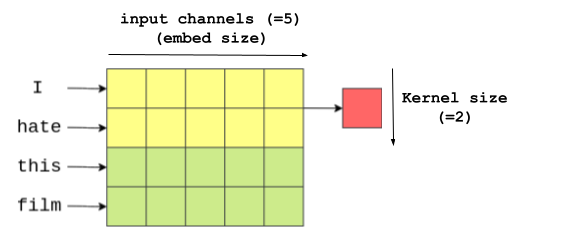

We'll run our tests in this notebook using the 2-dimensional convolutional model, but leave the implementation for the 1-dimensional model below to check out.

In [44]:
class CNN1d(nn.Module):
    def __init__(self, input_dim, emb_dim, output_dim, dropout, n_filters, filter_sizes):

        super().__init__()
        self.embedding = nn.Embedding(input_dim, emb_dim, padding_idx=pad_idx)
        self.convs = nn.ModuleList([
                                    nn.Conv1d(in_channels = emb_dim,
                                              out_channels = n_filters,
                                              kernel_size = fs)
                                    for fs in filter_sizes
                                    ])
        self.fc = nn.Linear(len(filter_sizes) * n_filters, output_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, text):
        #text = [batch size, sent len]
        embedded = self.embedding(text)

        #embedded = [batch size, sent len, emb dim]
        embedded = embedded.permute(0, 2, 1)
        #embedded = [batch size, emb dim, sent len]

        conved = [F.relu(conv(embedded)) for conv in self.convs]
        #conved_n = [batch size, n_filters, sent len - filter_sizes[n] + 1]

        pooled = [F.max_pool1d(conv, conv.shape[2]).squeeze(2) for conv in conved]
        #pooled_n = [batch size, n_filters]

        cat = self.dropout(torch.cat(pooled, dim = 1))
        #cat = [batch size, n_filters * len(filter_sizes)]

        return self.fc(cat)

In [45]:
def init_weights(m):
    if isinstance(m, nn.Linear):
        nn.init.xavier_normal_(m.weight)
        nn.init.zeros_(m.bias)
    elif isinstance(m, (nn.Conv2d, nn.Conv2d)):
        for name, param in m.named_parameters():
            if "weight" in name:
                nn.init.kaiming_normal_(param)  # Works well for CNNs
            elif "bias" in name:
                nn.init.zeros_(param)

In [46]:
def count_params(m):
    counts = [param.numel() for name, param in m.named_parameters() if param.requires_grad]
    for item in counts:
        print(f"{item:>6}")
    print(f"---------\n{sum(counts):>6}")

def accuracy(pred_logits, y_true):
    y_pred = torch.max(pred_logits.data, dim=1)[1]
    batch_accuracy = (y_pred == y_true).sum()
    accuracy = batch_accuracy / len(y_true)
    return accuracy

def elapsed_time(start_time, end_time):
    elapsed_time = end_time - start_time
    elapsed_mins = int(elapsed_time / 60)
    elapsed_secs = int(elapsed_time - (elapsed_mins * 60))
    return elapsed_mins, elapsed_secs

In [47]:
text_pipeline = lambda t: word2idx(tokenizer(t))
label_pipeline = lambda l: int(l)- 1   # for pytorch training, labels index to start from 0

def collate_batch(batch):
    labels, texts = [], []
    for (_label, _text) in batch:
        labels.append(label_pipeline(_label))
        processed_text = torch.tensor(text_pipeline(_text), dtype=torch.int64)
        texts.append(processed_text)
    return torch.tensor(labels, dtype=torch.int64), pad_sequence(texts, batch_first=True, padding_value=pad_idx)

In [48]:
def train_step(model, train_dataloader, optimizer, criterion, train_dataloader_length):
    train_loss = 0.0
    train_acc = 0.0
    model.train()
    for idx, (label, text) in enumerate(train_dataloader):
        label = label.to(device)
        text = text.to(device)
        optimizer.zero_grad()
        logits = model(text)
        loss = criterion(logits.squeeze(dim=1), label)
        acc = accuracy(logits, label)
        train_loss += loss.item()
        train_acc += acc.item()
        loss.backward()
        optimizer.step()
    train_epoch_loss = train_loss / train_dataloader_length
    train_epoch_acc = train_acc / train_dataloader_length
    return train_epoch_loss, train_epoch_acc

In [49]:
def val_step(model, val_dataloader, criterion, val_dataloader_length):
    val_loss = 0.0
    val_acc = 0.0
    model.eval()
    with torch.no_grad():
        for idx, (label, text) in enumerate(val_dataloader):
            label = label.to(device)
            text = text.to(device)
            logits = model(text)
            loss = criterion(logits.squeeze(dim=1), label)
            acc = accuracy(logits, label)
            val_loss += loss.item()
            val_acc += acc.item()
        val_epoch_loss = val_loss / val_dataloader_length
        val_epoch_acc = val_acc / val_dataloader_length
    return val_epoch_loss, val_epoch_acc

In [51]:
# Training
batch_size = 64

train_dataloader = DataLoader(train, batch_size=batch_size, shuffle=True, collate_fn=collate_batch)
val_dataloader = DataLoader(val, batch_size=batch_size, collate_fn=collate_batch)
test_dataloader = DataLoader(test, batch_size=batch_size, collate_fn=collate_batch)

train_loader_length = len(list(iter(train_dataloader)))
val_loader_length = len(list(iter(val_dataloader)))
test_loader_length = len(list(iter(test_dataloader)))

input_dim = len(word2idx)
embed_dim = 300
output_dim = 4
n_filters = 100
filter_sizes = [3, 4, 5]  # responsible for creating 3 x embed_dim, 4 x embed_dim, 5 x embed_dim filters to represent the relation between trigrams, 4grams and 5 grams
dropout = 0.5

model = CNNModel(input_dim, embed_dim, output_dim, n_filters, filter_sizes, dropout, pad_idx)
model.apply(init_weights)
model.to(device)

count_params(model)

# Load the subword embedding => FastText
fast_text = FastText(language="simple")
fast_vectors = fast_text.get_vecs_by_tokens(tokens=word2idx.get_itos()).to(device)
print(f"Fast Text Embeddings shape: {fast_vectors.shape}")  # (vocab, emb_dim=300)
model.embeddings.weight.data = fast_vectors                  # applied the fast text embedding as the initial weights

epochs = 5
best_loss = float("inf")
save_path = f"/content/{model.__class__.__name__}.pt"

optimizer = torch.optim.Adam(lr=1e-3, params=model.parameters())
criterion = nn.CrossEntropyLoss().to(device)

train_losses, train_accs, val_losses, val_accs = [], [], [], []

for epoch in range(epochs):
    start_time = time.time()
    train_loss, train_acc = train_step(model, train_dataloader, optimizer, criterion, train_loader_length)
    val_loss, val_acc = val_step(model, val_dataloader, criterion, val_loader_length)
    train_losses.append(train_loss)
    train_accs.append(train_acc)
    val_losses.append(val_loss)
    val_accs.append(val_acc)
    if val_loss < best_loss:
        best_loss = val_loss
        torch.save(model.state_dict(), save_path)
    end_time = time.time()
    elapsed_mins, elapsed_secs = elapsed_time(start_time, end_time)
    print(f'Epoch: {epoch+1:02} | Time: {elapsed_mins}m {elapsed_secs}s')
    print(f'\tTrain Loss: {train_loss:.3f} | Train Acc: {train_acc*100:.2f}%')
    print(f'\t Val. Loss: {val_loss:.3f} |  Val. Acc: {val_acc*100:.2f}%')

15769200
 90000
   100
120000
   100
150000
   100
  1200
     4
---------
16130704
Fast Text Embeddings shape: torch.Size([52564, 300])
Epoch: 01 | Time: 0m 19s
	Train Loss: 0.514 | Train Acc: 81.45%
	 Val. Loss: 0.338 |  Val. Acc: 88.85%
Epoch: 02 | Time: 0m 18s
	Train Loss: 0.304 | Train Acc: 89.82%
	 Val. Loss: 0.228 |  Val. Acc: 92.28%
Epoch: 03 | Time: 0m 17s
	Train Loss: 0.247 | Train Acc: 91.90%
	 Val. Loss: 0.199 |  Val. Acc: 93.37%
Epoch: 04 | Time: 0m 17s
	Train Loss: 0.226 | Train Acc: 92.64%
	 Val. Loss: 0.176 |  Val. Acc: 94.22%
Epoch: 05 | Time: 0m 17s
	Train Loss: 0.195 | Train Acc: 93.62%
	 Val. Loss: 0.162 |  Val. Acc: 94.61%


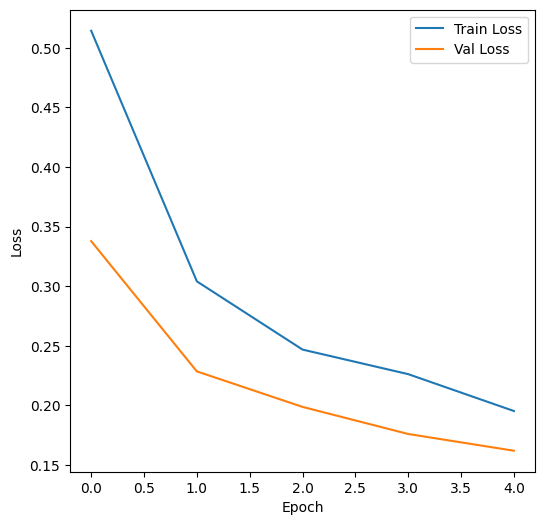

In [52]:
# Plotting
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(1, 1, 1)
ax.plot(train_losses, label="Train Loss")
ax.plot(val_losses, label="Val Loss")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Loss")
plt.show()

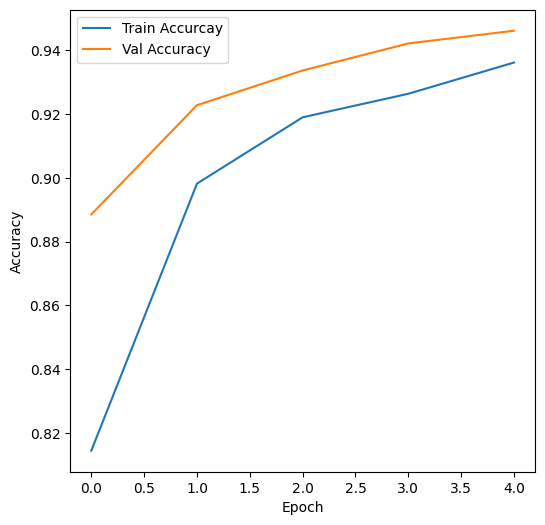

In [53]:
fig = plt.figure(figsize=(6, 6))
ax = fig.add_subplot(1, 1, 1)
ax.plot(train_accs, label="Train Accurcay")
ax.plot(val_accs, label="Val Accuracy")
plt.legend()
ax.set_xlabel("Epoch")
ax.set_ylabel("Accuracy")
plt.show()

In [54]:
# Test
model.load_state_dict(torch.load(save_path))
test_loss, test_acc = val_step(model, test_dataloader, criterion, test_loader_length)
print(f"\n Test Loss: {test_loss:3.5f} | Test Loss: {test_acc:3.5f}")


 Test Loss: 0.25585 | Test Loss: 0.91465


In [55]:
# Predict
def predict(text):
    with torch.no_grad():
        input = torch.tensor(text_pipeline(text)).to(device)
        input = input.reshape(1, -1)  # (bs, seq_len)
        logits = model(input)
        prediction = torch.max(logits.data, dim=1)[1]
        return prediction

predict("Google is now falling nonstop.  The price is really bad now.")

tensor([2], device='cuda:0')

World, Sports, Business, Sci/Tech